# Dataset A — Coalizão Fato ou Boato (TSE): EDA descritiva

**Projeto:** Impacto das fake news geradas por IA no eleitor brasileiro — Fase 2 do roteiro de trabalho.

**Fonte real dos dados:** [justicaeleitoral.jus.br/fato-ou-boato](https://www.justicaeleitoral.jus.br/fato-ou-boato), agregador oficial de checagens da Justiça Eleitoral (10 agências parceiras: AFP, Agência Lupa, Aos Fatos, Boatos.org, Comprova, E-Farsas, Estadão Verifica, Fato ou Fake, Justiça Eleitoral, UOL Confere).

**Escopo coletado:** a tag editorial **"fake news"** do site (267 checagens, população completa dessa tag) **mais 55 checagens adicionais genuinamente novas**, encontradas em 7 outras tags tematicamente relacionadas à desinformação eleitoral — `fraude` (85), `boletim de urna` (28), `código-fonte` (23), `totalização` (17), `biometria` (11), `resultado` (12) e `crime eleitoral` (4), população completa de cada uma. Essas 7 tags somam 151 itens únicos, dos quais 96 já estavam entre os 267 da tag "fake news" (sobreposição esperada, já que um item pode ter várias tags) — só os 55 que não apareciam em nenhuma outra coleta foram incorporados, com a(s) tag(s) de origem preservada(s) na coluna `tags_adicionais` para rastreabilidade total.

Total: **322 checagens reais**, de 11/10/2018 a 31/07/2026, coletadas via navegação real (Claude in Chrome) em 23/08/2026 e reproduzidas em `raw_scrape_dataset_a_tse.py` + `raw_scrape_dataset_a_extra_tags.py` / `dataset_a_fato_ou_boato_completo.csv`. Nenhum dado sintético foi usado nesta versão do notebook.

**Limitações honestas da coleta (importantes para a leitura dos resultados):**
- O site não expõe veredito, agência responsável ou tags temáticas como texto estruturado por item na listagem — apenas título, resumo e data. O veredito visual (selo "FALSO"/"BOATO"/"GOLPE") é uma imagem, não texto, e não foi possível extraí-lo sem OCR.
- Por isso, `veredito_estimado`, `rotulo_ia`, `categoria_macro` e `alvo_ataque` abaixo são **heurísticas textuais** (regras sobre título + resumo), não classificações oficiais da fonte — precisam de validação manual antes de qualquer teste inferencial definitivo (Fase 3).
- A tag "fake news" é uma entre ~68 tags do site; ela não cobre 100% do acervo (462 checagens no total, sem filtro) — o recorte aqui prioriza precisão temática (desinformação eleitoral) sobre cobertura total.


In [1]:

import re
import unicodedata
from datetime import date

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

%matplotlib inline
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_colwidth", 90)


## 1. Carga dos dados reais

In [2]:

df = pd.read_csv("../data/processed/dataset_a_fato_ou_boato_completo.csv", parse_dates=["data_publicacao_checagem"])
print(f"Linhas: {len(df)} | Colunas: {list(df.columns)}")
print(df["fonte_tag"].value_counts())
df.head(3)


Linhas: 322 | Colunas: ['id_checagem', 'titulo', 'descricao_resumo', 'data_publicacao_checagem', 'pagina_b_start', 'fonte_listagem', 'fonte_tag', 'tags_adicionais']
fonte_tag
fake news        267
tag adicional     55
Name: count, dtype: int64


,id_checagem,titulo,descricao_resumo,data_publicacao_checagem,pagina_b_start,fonte_listagem,fonte_tag,tags_adicionais
0,FOB-0248,"Eleições 2018: votos foram anulados por eleitores, e não pela Justiça Eleitoral",Texto que circulou no WhatsApp divulgava informações erradas a respeito da votação,2018-10-11,240.0,https://www.justicaeleitoral.jus.br/fato-ou-boato/@@search?SearchableText=&b_start%3Ai...,fake news,NaN
1,FOB-0250,Boletim de urna com 9.909 votos em candidato à Presidência nas Eleições Gerais de 2018...,Documento foi adulterado para dar a entender que número de votos foi superior à quanti...,2018-10-11,240.0,https://www.justicaeleitoral.jus.br/fato-ou-boato/@@search?SearchableText=&b_start%3Ai...,fake news,NaN
2,FOB-0247,Eleições 2018: é falso que boletim de urna tenham registrado 9.909 votos para candidat...,Montagem foi compartilhada para lançar dúvida sobre lisura do pleito ao insinuar que s...,2018-10-11,240.0,https://www.justicaeleitoral.jus.br/fato-ou-boato/@@search?SearchableText=&b_start%3Ai...,fake news,NaN


## 2. Limpeza e tratamento de valores ausentes

O resumo (`descricao_resumo`) pode vir vazio quando o site não exibiu uma linha de contexto abaixo do título — ocorre em alguns itens tanto da tag "fake news" quanto das tags adicionais, onde é ainda mais comum. Não há título ou data ausentes nesta coleta (ambos foram exigidos como chave essencial durante a extração).

In [3]:

missing_pct = df.isna().mean().mul(100).round(1)
missing_pct = missing_pct[missing_pct > 0]
vazio_pct = (df["descricao_resumo"].str.len() == 0).mean() * 100
print("Percentual de NaN por coluna:\n", missing_pct if len(missing_pct) else "nenhuma coluna com NaN")
print(f"\nResumo vazio (string ''): {vazio_pct:.1f}% dos itens")

dup = df.duplicated(subset=["titulo", "data_publicacao_checagem"]).sum()
print(f"Duplicatas exatas (título + data): {dup}")

df["tamanho_texto"] = (df["titulo"] + " " + df["descricao_resumo"]).str.len()
q1, q3 = df["tamanho_texto"].quantile([0.25, 0.75])
iqr = q3 - q1
limite_sup = q3 + 3 * iqr
df["outlier_tamanho_texto"] = df["tamanho_texto"] > limite_sup
print(f"Outliers de tamanho (regra 3xIQR, não removidos, apenas sinalizados): {df['outlier_tamanho_texto'].sum()}")


Percentual de NaN por coluna:
 descricao_resumo     2.8
pagina_b_start      17.1
tags_adicionais     82.9
dtype: float64

Resumo vazio (string ''): 0.0% dos itens
Duplicatas exatas (título + data): 0
Outliers de tamanho (regra 3xIQR, não removidos, apenas sinalizados): 0


## 3. Engenharia de features

### 3.1 Normalização de texto e heurística de rótulo de IA
Como a fonte não rotula peças como "geradas por IA", aplicamos um dicionário de termos (mesma lógica usada no Dataset B, Seção 5, para permitir comparação entre fontes) sobre título + resumo.

In [4]:

def normalize_text(text):
    if not isinstance(text, str):
        return ""
    text = unicodedata.normalize("NFKD", text).encode("ascii", "ignore").decode("ascii")
    return re.sub(r"\s+", " ", text.lower()).strip()

AI_PATTERNS = {
    "IA_audio": [r"\baudio\w* clonad\w*", r"\bvoz clonad\w*", r"\bclonagem de voz\b"],
    "IA_video": [r"\bdeepfake\w*", r"\bvideo\w* (manipulad\w*|falsificad\w*|gerad\w* por ia)"],
    "IA_texto": [r"\bgerad\w* por (ia|intelig\w+ artificial)", r"\btexto\w* (gerad\w*|escrit\w*) por ia",
                 r"\bchatgpt\b", r"\bllm\b"],
    "IA_imagem": [r"\bimagem\w* (gerad\w*|manipulad\w*) por ia", r"\bfoto\w* gerad\w* por ia",
                  r"\bimagem\w* sintetic\w*"],
}
GENERIC_AI_PATTERN = re.compile(r"\b(intelig\w+ artificial|\bia\b|deepfake\w*)")

def match_ai_label(texto_norm):
    for label, patterns in AI_PATTERNS.items():
        if any(re.search(p, texto_norm) for p in patterns):
            return label
    if GENERIC_AI_PATTERN.search(texto_norm):
        return "IA_indeterminado"
    return "Tradicional"

df["texto_norm"] = (df["titulo"].map(normalize_text) + " " + df["descricao_resumo"].map(normalize_text))
df["rotulo_ia"] = df["texto_norm"].map(match_ai_label)
df["rotulo_ia_bin"] = np.where(df["rotulo_ia"] != "Tradicional", "IA", "Tradicional")

df["rotulo_ia_bin"].value_counts()


rotulo_ia_bin
Tradicional    322
Name: count, dtype: int64

### 3.2 Veredito estimado (a partir do padrão lexical do título)

O site mostra o veredito como selo visual (imagem), não como texto — por isso aproximamos o veredito pelo padrão de abertura do título, um recurso editorial consistente nas 322 checagens reais (ex.: "É falso...", "É mentira...", "Golpe:...", "Boato:...").

In [5]:

def estimar_veredito(titulo):
    t = normalize_text(titulo)
    if re.match(r"^golpe\b", t):
        return "Golpe/Scam"
    if re.match(r"^(e falso|nao e verdade|nao houve|nao e|foi falso)", t):
        return "Falso"
    if re.match(r"^(e mentira|mente|mentiu|mentiram)", t) or " mente " in t or " mentiu " in t:
        return "Mentira/Distorção"
    if re.match(r"^(e enganoso|engana|enganam)", t) or " engana " in t:
        return "Enganoso"
    if re.match(r"^(boato|e boato)", t):
        return "Boato"
    return "Não classificado pelo padrão do título"

df["veredito_estimado"] = df["titulo"].map(estimar_veredito)
df["veredito_estimado"].value_counts()


veredito_estimado
Não classificado pelo padrão do título    243
Falso                                      41
Mentira/Distorção                          23
Enganoso                                    9
Boato                                       5
Golpe/Scam                                  1
Name: count, dtype: int64

### 3.3 Categoria temática macro (a partir de título + resumo)
Sem acesso às tags oficiais por item nesta coleta, aproximamos a categoria macro por palavras-chave — mapeamento alinhado ao vocabulário real de 68 tags do próprio site (urna, biometria, código-fonte, mesário, apuração, totalização, candidatos, etc.).

In [6]:

CATEGORIA_KEYWORDS = {
    "Sistema Eletrônico de Votação": ["urna", "biometria", "codigo-fonte", "codigo fonte",
                                       "ciberseguranca", "certificacao", "voto impresso", "software"],
    "Processo Eleitoral": ["mesario", "secao eleitoral", "apuracao", "totalizacao", "fraude",
                            "zona eleitoral", "boletim de urna", "titulo de eleitor"],
    "Candidato/Partido": ["candidato", "candidata", "partido", "presidente", "deputado", "senador",
                           "governador", "vereador", "prefeito"],
    "Instituição/Justiça Eleitoral": ["tse", "tre", "stf", "ministro", "justica eleitoral"],
}

def categoria_macro(texto_norm):
    for cat, kws in CATEGORIA_KEYWORDS.items():
        if any(kw in texto_norm for kw in kws):
            return cat
    return "Outros"

df["categoria_macro"] = df["texto_norm"].map(categoria_macro)

ATTACK_KEYWORDS = {
    "candidato_pessoa": ["carater", "honestidade", "vida pessoal", "familia", "saude",
                          "corrupcao pessoal", "traicao", "diploma", "patrimonio pessoal", "morte", "morreu"],
    "urna_processo": ["urna", "biometria", "totalizacao", "apuracao", "sistema eletronico",
                       "fraude eleitoral", "codigo-fonte", "codigo fonte", "seguranca do voto"],
}

def alvo_ataque(texto_norm):
    score_p = sum(kw in texto_norm for kw in ATTACK_KEYWORDS["candidato_pessoa"])
    score_u = sum(kw in texto_norm for kw in ATTACK_KEYWORDS["urna_processo"])
    if score_p == 0 and score_u == 0:
        return "indeterminado"
    return "candidato_pessoa" if score_p >= score_u else "urna_processo"

df["alvo_ataque"] = df["texto_norm"].map(alvo_ataque)
df[["categoria_macro", "alvo_ataque"]].apply(lambda s: s.value_counts()).fillna(0).astype(int)


,categoria_macro,alvo_ataque
Candidato/Partido,34,0
Instituição/Justiça Eleitoral,47,0
Outros,28,0
Processo Eleitoral,64,0
Sistema Eletrônico de Votação,149,0
candidato_pessoa,0,4
indeterminado,0,154
urna_processo,0,164


### 3.4 Distância até a eleição (dias)
O ciclo eleitoral mais próximo é inferido diretamente da **data real** de publicação (não de uma tag), usando a data do 1º turno de cada eleição geral/municipal.

In [7]:

DATAS_TURNO_1 = {
    2018: date(2018, 10, 7), 2020: date(2020, 11, 15), 2022: date(2022, 10, 2),
    2024: date(2024, 10, 6), 2026: date(2026, 10, 4),
}

def ciclo_e_dias(data_pub):
    ano = data_pub.year
    anos_disponiveis = sorted(DATAS_TURNO_1.keys())
    ciclo = min(anos_disponiveis, key=lambda a: abs(a - ano))
    turno = DATAS_TURNO_1[ciclo]
    return pd.Series({"ciclo_eleitoral_estimado": ciclo,
                       "dias_para_eleicao": (data_pub.date() - turno).days})

df = df.join(df["data_publicacao_checagem"].apply(ciclo_e_dias))
df[["data_publicacao_checagem", "ciclo_eleitoral_estimado", "dias_para_eleicao"]].sample(5, random_state=1)


,data_publicacao_checagem,ciclo_eleitoral_estimado,dias_para_eleicao
262,2022-12-11,2022,70
174,2022-10-07,2022,5
157,2022-10-03,2022,1
246,2022-11-25,2022,54
150,2022-10-01,2022,-1


## 4. EDA descritiva

In [8]:

print("=== Distribuição por ciclo eleitoral estimado ===")
print(df["ciclo_eleitoral_estimado"].value_counts().sort_index())

print("\n=== Distribuição rótulo IA (heurística textual) ===")
print(df["rotulo_ia"].value_counts())

print("\n=== Estatísticas descritivas (dias até a eleição) ===")
print(df["dias_para_eleicao"].describe().round(1))


=== Distribuição por ciclo eleitoral estimado ===
ciclo_eleitoral_estimado
2018     24
2020     70
2022    203
2024     22
2026      3
Name: count, dtype: int64

=== Distribuição rótulo IA (heurística textual) ===
rotulo_ia
Tradicional    322
Name: count, dtype: int64

=== Estatísticas descritivas (dias até a eleição) ===
count    322.0
mean      35.4
std      129.2
min     -240.0
25%       -4.0
50%       14.0
75%       54.0
max      430.0
Name: dias_para_eleicao, dtype: float64


In [9]:

tabela_crosstab = pd.crosstab(df["rotulo_ia_bin"], df["categoria_macro"], normalize="index").round(3)
tabela_crosstab


categoria_macro,Candidato/Partido,Instituição/Justiça Eleitoral,Outros,Processo Eleitoral,Sistema Eletrônico de Votação
rotulo_ia_bin,,,,,
Tradicional,0.106,0.146,0.087,0.199,0.463


In [10]:

tabela_abs = pd.crosstab(df["rotulo_ia_bin"], df["categoria_macro"])
chi2, p, dof, _ = stats.chi2_contingency(tabela_abs)
n = tabela_abs.to_numpy().sum()
v_cramer = np.sqrt(chi2 / (n * (min(tabela_abs.shape) - 1)))
print(f"Qui-quadrado exploratório (rótulo IA x categoria temática): chi2={chi2:.3f}, p={p:.4f}, "
      f"gl={dof}, V de Cramér={v_cramer:.3f}")
print("\n(Preview descritivo apenas — com n=", int((df['rotulo_ia_bin']=='IA').sum()),
      "itens heuristicamente rotulados como IA, o teste formal de H2/H4 deve rodar na Fase 3",
      "sobre o rótulo validado manualmente.)")


Qui-quadrado exploratório (rótulo IA x categoria temática): chi2=0.000, p=1.0000, gl=0, V de Cramér=nan

(Preview descritivo apenas — com n= 0 itens heuristicamente rotulados como IA, o teste formal de H2/H4 deve rodar na Fase 3 sobre o rótulo validado manualmente.)


/tmp/ipykernel_7978/3860478985.py:4: RuntimeWarning: invalid value encountered in divide
  v_cramer = np.sqrt(chi2 / (n * (min(tabela_abs.shape) - 1)))


## 5. Visualizações

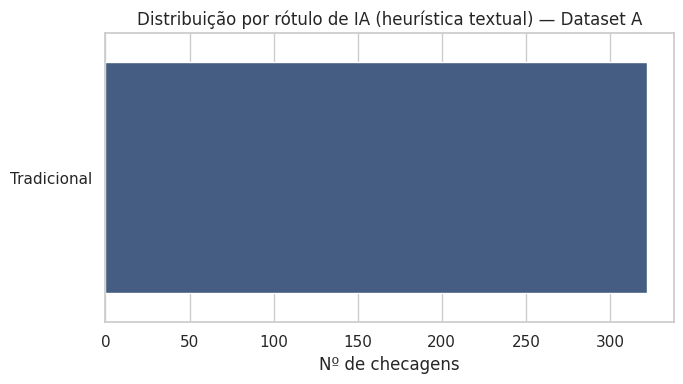

In [11]:

fig, ax = plt.subplots(figsize=(7, 4))
sns.countplot(data=df, y="rotulo_ia", order=df["rotulo_ia"].value_counts().index, color="#3B5B8C", ax=ax)
ax.set_title("Distribuição por rótulo de IA (heurística textual) — Dataset A")
ax.set_xlabel("Nº de checagens"); ax.set_ylabel("")
plt.tight_layout(); plt.show()


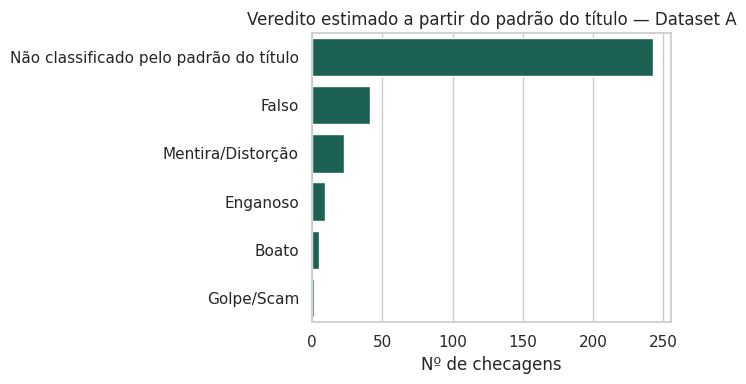

In [12]:

fig, ax = plt.subplots(figsize=(7, 4))
sns.countplot(data=df, y="veredito_estimado", order=df["veredito_estimado"].value_counts().index,
              color="#0F6E5C", ax=ax)
ax.set_title("Veredito estimado a partir do padrão do título — Dataset A")
ax.set_xlabel("Nº de checagens"); ax.set_ylabel("")
plt.tight_layout(); plt.show()


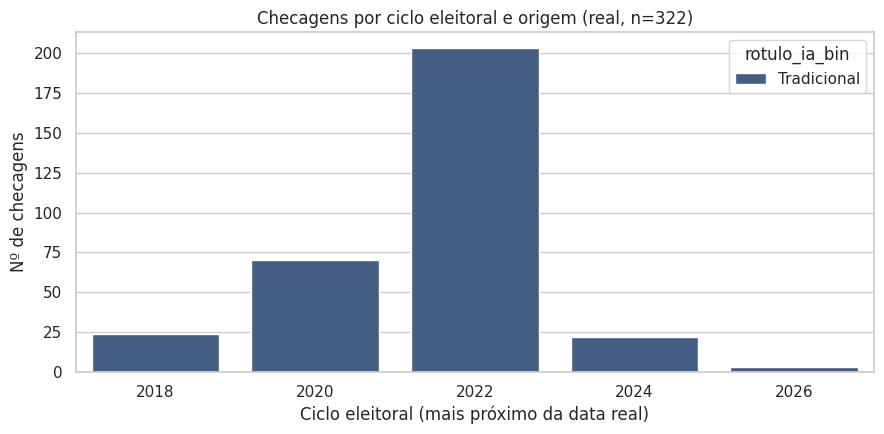

In [13]:

fig, ax = plt.subplots(figsize=(9, 4.5))
ordem_ciclos = sorted(df["ciclo_eleitoral_estimado"].unique())
sns.countplot(data=df, x="ciclo_eleitoral_estimado", hue="rotulo_ia_bin", order=ordem_ciclos,
              palette={"IA": "#A8501C", "Tradicional": "#3B5B8C"}, ax=ax)
ax.set_title("Checagens por ciclo eleitoral e origem (real, n=322)")
ax.set_xlabel("Ciclo eleitoral (mais próximo da data real)"); ax.set_ylabel("Nº de checagens")
plt.tight_layout(); plt.show()


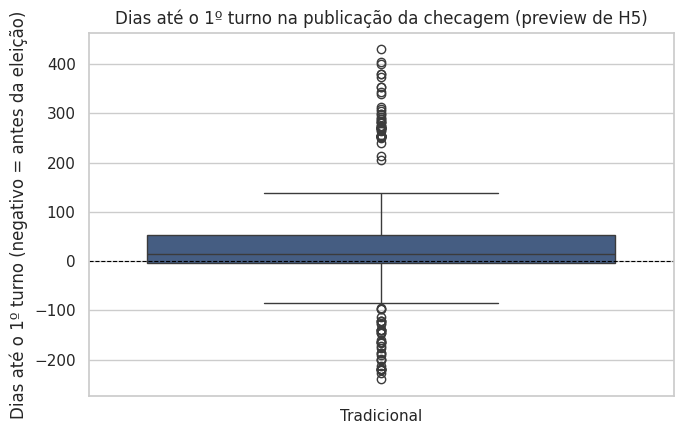

In [14]:

fig, ax = plt.subplots(figsize=(7, 4.5))
sns.boxplot(data=df, x="rotulo_ia_bin", y="dias_para_eleicao", hue="rotulo_ia_bin",
            palette={"IA": "#A8501C", "Tradicional": "#3B5B8C"}, legend=False, ax=ax)
ax.axhline(0, color="black", linewidth=0.8, linestyle="--")
ax.set_title("Dias até o 1º turno na publicação da checagem (preview de H5)")
ax.set_ylabel("Dias até o 1º turno (negativo = antes da eleição)"); ax.set_xlabel("")
plt.tight_layout(); plt.show()


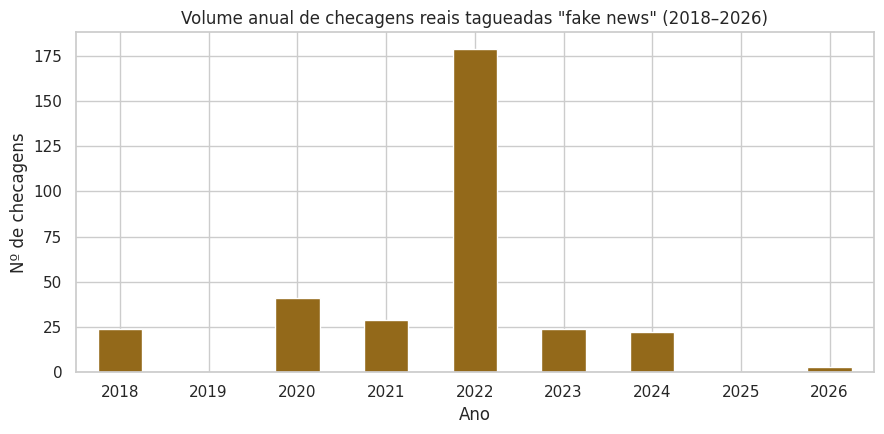

In [15]:

fig, ax = plt.subplots(figsize=(9, 4.5))
df.set_index("data_publicacao_checagem").resample("YE").size().plot(kind="bar", color="#93691A", ax=ax)
ax.set_title("Volume anual de checagens reais tagueadas \"fake news\" (2018–2026)")
ax.set_xlabel("Ano"); ax.set_ylabel("Nº de checagens")
ax.set_xticklabels([str(t.year) if hasattr(t, "year") else t for t in
                     df.set_index("data_publicacao_checagem").resample("YE").size().index], rotation=0)
plt.tight_layout(); plt.show()


## 6. Salvar dataset enriquecido

In [16]:

df.drop(columns=["texto_norm"]).to_csv("../data/processed/dataset_a_fato_ou_boato_enriquecido.csv", index=False)
print("Salvo: ../data/processed/dataset_a_fato_ou_boato_enriquecido.csv —", len(df), "linhas")
df.drop(columns=["texto_norm"]).sample(5, random_state=7)


Salvo: ../data/processed/dataset_a_fato_ou_boato_enriquecido.csv — 322 linhas


,id_checagem,titulo,descricao_resumo,data_publicacao_checagem,pagina_b_start,fonte_listagem,fonte_tag,tags_adicionais,tamanho_texto,outlier_tamanho_texto,rotulo_ia,rotulo_ia_bin,veredito_estimado,categoria_macro,alvo_ataque,ciclo_eleitoral_estimado,dias_para_eleicao
84,FOB-0218,Inquérito da PF não investiga fraude no processo de votação,NaN,2021-08-17,210.0,https://www.justicaeleitoral.jus.br/fato-ou-boato/@@search?SearchableText=&b_start%3Ai...,fake news,NaN,NaN,False,Tradicional,Tradicional,Não classificado pelo padrão do título,Processo Eleitoral,indeterminado,2020,275
221,FOB-0092,Tweet erra ao afirmar que seção eleitoral do Pará não teve nenhum voto para candidato ...,Eleitor propagou informações equivocadas ao comentar publicação que questionava result...,2022-11-07,90.0,https://www.justicaeleitoral.jus.br/fato-ou-boato/@@search?SearchableText=&b_start%3Ai...,fake news,NaN,199.0,False,Tradicional,Tradicional,Não classificado pelo padrão do título,Processo Eleitoral,indeterminado,2022,36
184,FOB-0129,Boletins de urna mostrados em vídeo não são de MG nem provam fraude,"As imagens foram registradas no Rio de Janeiro, como confirmou o TRE-RJ",2022-10-13,120.0,https://www.justicaeleitoral.jus.br/fato-ou-boato/@@search?SearchableText=&b_start%3Ai...,fake news,NaN,139.0,False,Tradicional,Tradicional,Não classificado pelo padrão do título,Sistema Eletrônico de Votação,urna_processo,2022,11
240,FOB-0080,Não é verdade que Bolsonaro não teve votos em São Gabriel da Cachoeira (AM),"Candidato à reeleição conseguiu, respectivamente nos 1º e 2º turnos, 17,52% e 19,36% d...",2022-11-22,70.0,https://www.justicaeleitoral.jus.br/fato-ou-boato/@@search?SearchableText=&b_start%3Ai...,fake news,NaN,184.0,False,Tradicional,Tradicional,Falso,Candidato/Partido,indeterminado,2022,51
99,FOB-0206,Aplicativo que simula votação em político não tem relação com urnas eletrônicas oficiais,TSE não utiliza aparelho celular para colher voto do eleitorado,2022-02-25,200.0,https://www.justicaeleitoral.jus.br/fato-ou-boato/@@search?SearchableText=&b_start%3Ai...,fake news,NaN,152.0,False,Tradicional,Tradicional,Não classificado pelo padrão do título,Sistema Eletrônico de Votação,urna_processo,2022,-219


## 7. Limitações e próximos passos

- **Veredito e categoria são heurísticos.** Antes da Fase 3 (testes formais de H1–H5), uma amostra deve ser revisada manualmente para medir a taxa de acerto dessas regras (ex.: Cohen's kappa entre a heurística e uma checagem humana).
- **Sem métricas de engajamento nesta fonte.** O TSE não publica alcance/compartilhamentos — H1 (velocidade/engajamento) depende do cruzamento com o Dataset B na Fase 3.
- **Cobertura do site:** 322 dos 462 itens totais (267 da tag "fake news" + 55 novos de 7 tags adicionais tematicamente relacionadas). Os ~140 itens ainda fora deste recorte são majoritariamente alertas de golpes financeiros/phishing (ex.: cobrança falsa de CNPJ de campanha, "Meu Título Digital") — fora do escopo de desinformação eleitoral do estudo, não de negligência na coleta.
- **Tags adicionais podem trazer o mesmo viés de seleção da tag "fake news"** — todas vêm do mesmo agregador e das mesmas 10 agências parceiras, então a expansão aumenta o volume mas não diversifica a fonte. Para diversificar a fonte de fato, o Dataset B (Aos Fatos) continua sendo o complemento necessário.
- Próximo notebook: `02_dataset_b_aosfatos_eda.ipynb`, que já traz veredito e tema como **classificação editorial real** (não heurística) do Aos Fatos, permitindo comparar a precisão da heurística acima.
